# DL — CNN-LSTM (Hybrid: Convolutional + LSTM): OHLCV vs OHLCV + Indicators
### TCS Stock Price Prediction | Deep Learning — CNN-LSTM (Hybrid: Convolutional + LSTM)
**Target:** Next-day Return → back-converted to Price | **Seeds:** 42 | **Test rows:** same as ML notebooks (~1067)


## Why CNN-LSTM for Stock Price Prediction?
> **CNN-LSTM** combines Conv1D for local pattern extraction with LSTM for sequential memory.  
> The CNN layer acts as a feature extractor detecting short-term price patterns,  
> then passes enriched features to LSTM for temporal modelling.


In [1]:
# Dependencies already installed in environment
# !pip install mplfinance scikit-learn -q
print('Dependencies ready!')


Dependencies ready!


---
## Step 0: Reproducibility — Set All Random Seeds to 42
Setting `numpy`, `python random`, and `tensorflow` seeds to **42** for fully reproducible results.


In [2]:
import os, random
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['PYTHONHASHSEED'] = '42'
random.seed(42)

import numpy as np
np.random.seed(42)

import tensorflow as tf
tf.random.set_seed(42)

# Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Conv1D, MaxPooling1D, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('All imports done! TensorFlow version:', tf.__version__)
print('All random seeds set to 42.')


All imports done! TensorFlow version: 2.21.0
All random seeds set to 42.


---
## Step 1: Load TCS Dataset
Reading `TCS.csv` (skiprows=[1,2]), parsing date index, keeping OHLCV columns, dropping NaN rows.


In [3]:
df = pd.read_csv('TCS.csv', skiprows=[1, 2])
if 'Price' in df.columns:
    df.rename(columns={'Price': 'Date'}, inplace=True)
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df = df.sort_index()[['Open', 'High', 'Low', 'Close', 'Volume']]

for col in ['Open', 'High', 'Low', 'Close', 'Volume']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.dropna(inplace=True)
print(f'Shape: {df.shape}')
print(f'Date range: {df.index.min().date()} to {df.index.max().date()}')
df.head()


Shape: (5363, 5)
Date range: 2005-01-03 to 2026-09-23


,Open,High,Low,Close,Volume
Date,,,,,
2005-01-03,106.283498,107.973897,106.283498,107.700127,4734168
2005-01-04,107.440734,107.759077,106.100513,106.745155,4979104
2005-01-05,106.660803,106.660803,101.893625,105.451103,9604320
2005-01-06,105.053169,107.122398,102.864561,105.089775,8006888
2005-01-07,105.848984,107.042770,104.468971,106.641655,7623136


In [4]:
print('Missing values per column:')
print(df.isnull().sum())
print(f'Volume == 0: {(df["Volume"] == 0).sum()} rows')


Missing values per column:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Volume == 0: 9 rows


In [5]:
print('Dataset Statistics:')
display(df.describe().round(2))


Dataset Statistics:


,Open,High,Low,Close,Volume
count,5363.00,5363.00,5363.00,5363.00,5363.00
mean,1337.33,1350.53,1323.25,1336.56,3350520.35
std,1182.66,1192.74,1172.07,1182.00,2819411.07
min,75.39,78.16,69.06,75.09,0.00
25%,272.82,276.23,269.14,272.56,1853218.00
50%,954.48,961.94,946.02,953.56,2650784.00
75%,2371.06,2401.41,2337.23,2363.71,3987019.00
max,4228.90,4243.92,4169.75,4208.34,88067154.00


---
## Step 2: Exploratory Data Analysis (EDA)
**Graphs:** Close price history | Candlestick (last 200 days) | Volume bar | OHLC line chart.


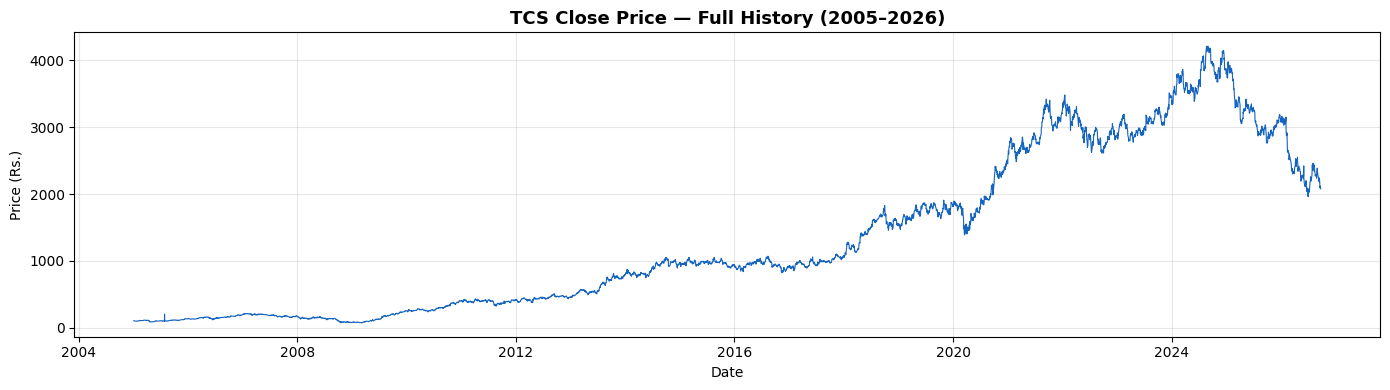

In [6]:
# Full history Close price
plt.figure(figsize=(14, 4))
plt.plot(df['Close'], color='#1565C0', lw=0.8)
plt.title('TCS Close Price — Full History (2005–2026)', fontsize=13, fontweight='bold')
plt.xlabel('Date'); plt.ylabel('Price (Rs.)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


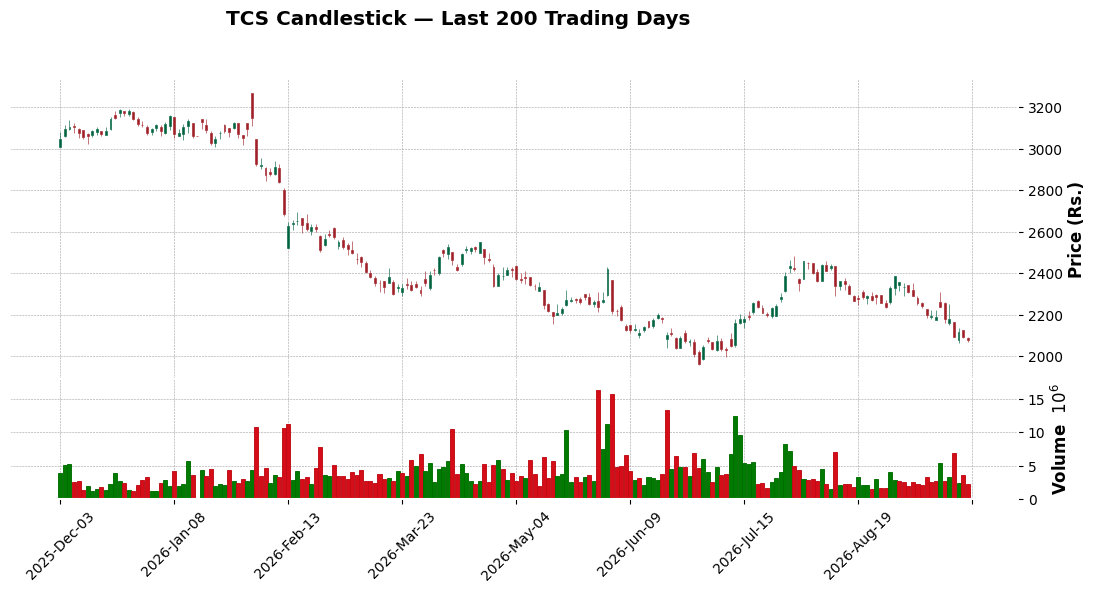

In [7]:
# Candlestick — Last 200 trading days
candle_df = df.tail(200).copy()
candle_df.index = pd.DatetimeIndex(candle_df.index)
mpf.plot(candle_df, type='candle', style='charles',
         title='TCS Candlestick — Last 200 Trading Days',
         ylabel='Price (Rs.)', volume=True,
         figsize=(14, 6), warn_too_much_data=400)


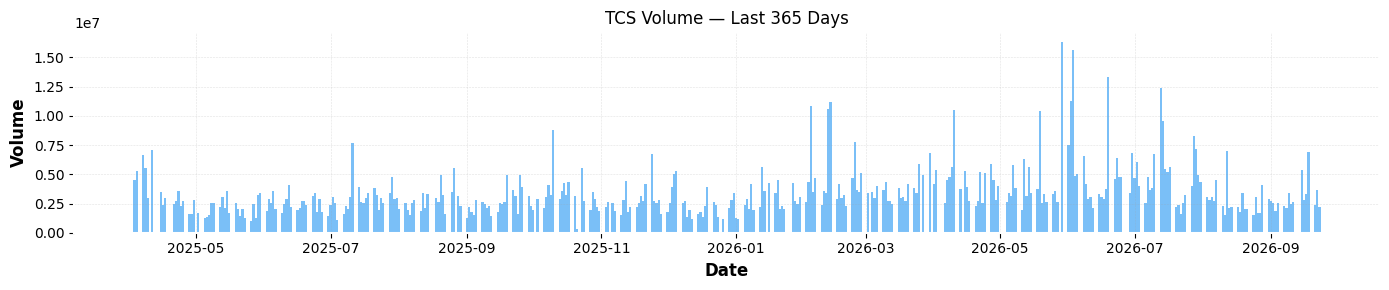

In [8]:
# Volume — Last 365 days
vol_df = df.tail(365)
plt.figure(figsize=(14, 3))
plt.bar(vol_df.index, vol_df['Volume'], color='#42A5F5', alpha=0.7, width=1)
plt.title('TCS Volume — Last 365 Days')
plt.xlabel('Date'); plt.ylabel('Volume')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


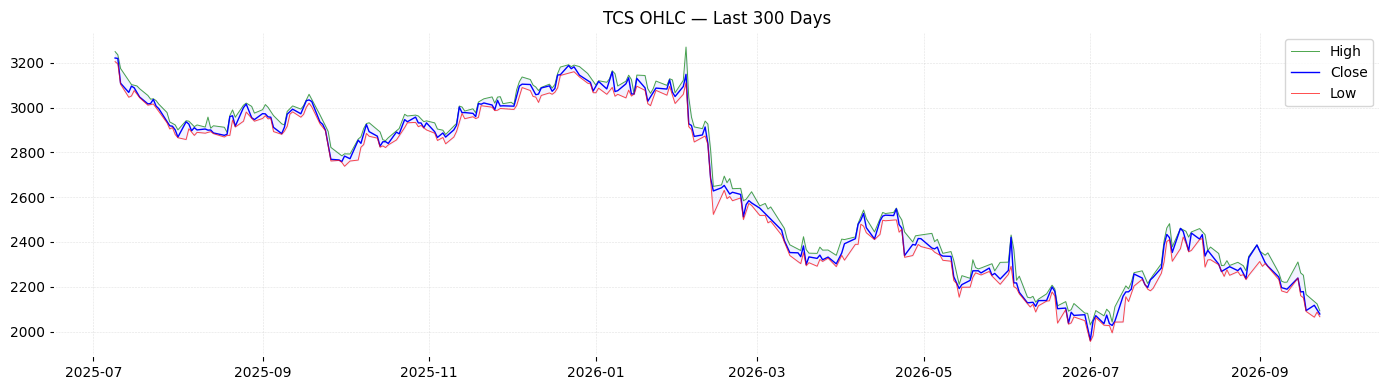

In [9]:
# OHLC line chart — last 300 days
ohlc_df = df.tail(300)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ohlc_df.index, ohlc_df['High'],  label='High',  color='green', lw=0.7, alpha=0.7)
ax.plot(ohlc_df.index, ohlc_df['Close'], label='Close', color='blue',  lw=1.0)
ax.plot(ohlc_df.index, ohlc_df['Low'],   label='Low',   color='red',   lw=0.7, alpha=0.7)
ax.fill_between(ohlc_df.index, ohlc_df['Low'], ohlc_df['High'], alpha=0.05, color='blue')
ax.set_title('TCS OHLC — Last 300 Days'); ax.legend()
ax.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


---
## Step 3: Define Return Target & Train-Test Split (80/20)
**Target:** `y_ret = Next_Close / Close - 1` (next-day simple return, NOT raw price)  
**Split:** ~4296 train rows | ~1067 test rows — same as ML notebooks.  
First test sequence allowed to look back into train end (past data, not leakage).


In [10]:
LOOK_BACK = 60   # 60-day sequence window (standard in literature)
SET_A     = ['Open', 'High', 'Low', 'Close', 'Volume']

# ── Build return-based target ──────────────────────────────────────
df_work = df.copy()
df_work['Next_Close']  = df_work['Close'].shift(-1)
df_work['Target_Ret']  = df_work['Next_Close'] / df_work['Close'] - 1   # next-day return

# Store close/next BEFORE slicing to avoid duplicate column issue
close_series = df_work['Close'].copy()
next_series  = df_work['Next_Close'].copy()
ret_series   = df_work['Target_Ret'].copy()

# Align everything on the same index (drop rows where target is NaN)
valid_idx = ret_series.dropna().index
df_A = df_work.loc[valid_idx, SET_A].copy()
y_ret_A    = ret_series.loc[valid_idx].values       # returns (target)
close_A    = close_series.loc[valid_idx].values     # today's close
next_A     = next_series.loc[valid_idx].values      # actual next-day close

X_A = df_A[SET_A].values

n_tr = int(len(X_A) * 0.8)
X_A_train, X_A_test       = X_A[:n_tr],     X_A[n_tr:]
y_A_train, y_A_test       = y_ret_A[:n_tr], y_ret_A[n_tr:]
close_A_train, close_A_test = close_A[:n_tr], close_A[n_tr:]
next_A_train,  next_A_test  = next_A[:n_tr],  next_A[n_tr:]

print(f'Total rows (after dropna): {len(X_A)}')
print(f'Train: {X_A_train.shape}  |  Test: {X_A_test.shape}  (same ~1067 test rows as ML notebooks)')
print(f'y_A_train stats -> mean={y_A_train.mean():.4f}  std={y_A_train.std():.4f}')


Total rows (after dropna): 5362
Train: (4289, 5)  |  Test: (1073, 5)  (same ~1067 test rows as ML notebooks)
y_A_train stats -> mean=0.0011  std=0.0258


### Data Inspection — Set A Stats


In [11]:
print('Set A — OHLCV (5 features), modelling rows only')
print('='*65)
display(pd.DataFrame(X_A, columns=SET_A).describe().round(2))


Set A — OHLCV (5 features), modelling rows only


,Open,High,Low,Close,Volume
count,5362.00,5362.00,5362.00,5362.00,5362.00
mean,1337.19,1350.39,1323.11,1336.43,3350729.62
std,1182.73,1192.81,1172.13,1182.07,2819632.36
min,75.39,78.16,69.06,75.09,0.00
25%,272.74,276.21,269.09,272.51,1853135.00
50%,954.43,961.91,945.98,953.46,2650817.00
75%,2371.18,2401.45,2338.16,2364.35,3987605.50
max,4228.90,4243.92,4169.75,4208.34,88067154.00


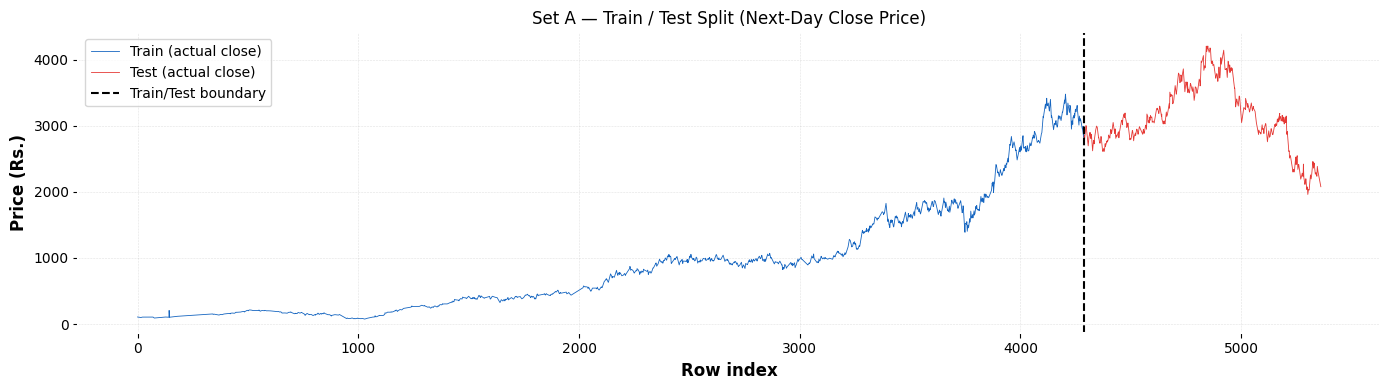

In [12]:
# Train vs Test split visualization (price)
n_te = len(next_A_test)
plt.figure(figsize=(14, 4))
plt.plot(range(n_tr), next_A_train, color='#1565C0', lw=0.6, label='Train (actual close)')
plt.plot(range(n_tr, n_tr + n_te), next_A_test, color='#E53935', lw=0.6, label='Test (actual close)')
plt.axvline(n_tr, color='black', lw=1.5, linestyle='--', label='Train/Test boundary')
plt.title('Set A — Train / Test Split (Next-Day Close Price)')
plt.xlabel('Row index'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


---
---
# Part A: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


---
---
# Part A: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [13]:
# StandardScaler for features (fit on train only)
scaler_XA = StandardScaler()
X_A_tr_sc = scaler_XA.fit_transform(X_A_train)
X_A_te_sc = scaler_XA.transform(X_A_test)

# StandardScaler for return target (fit on train only)
scaler_yA = StandardScaler()
y_A_tr_sc = scaler_yA.fit_transform(y_A_train.reshape(-1, 1)).flatten()
y_A_te_sc = scaler_yA.transform(y_A_test.reshape(-1, 1)).flatten()

print('Feature scaler — train mean/std:', scaler_XA.mean_.round(2), '/', scaler_XA.scale_.round(2))
print('Target scaler  — train mean/std:', round(scaler_yA.mean_[0],6), '/', round(scaler_yA.scale_[0],6))


Feature scaler — train mean/std: [8.90650000e+02 9.00290000e+02 8.80270000e+02 8.90140000e+02
 3.53575654e+06] / [8.31000000e+02 8.38710000e+02 8.22440000e+02 8.30360000e+02
 3.01040163e+06]
Target scaler  — train mean/std: 0.00107 / 0.025775


---
---
# Part A: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [14]:
def create_seq(X_sc, y_sc, lb=60):
    """
    Create (X, y) sequences of length lb.
    For test set, the first lb rows of X_sc may overlap with train end
    — that is intentional and allowed (past data only).
    """
    Xs, ys = [], []
    for i in range(lb, len(X_sc)):
        Xs.append(X_sc[i-lb:i])
        ys.append(y_sc[i])
    return np.array(Xs, dtype='float32'), np.array(ys, dtype='float32')

# For test sequences we concatenate last LOOK_BACK train rows with test rows
X_A_joined = np.vstack([X_A_tr_sc[-LOOK_BACK:], X_A_te_sc])
y_A_joined = np.concatenate([y_A_tr_sc[-LOOK_BACK:], y_A_te_sc])

X_A_tr_seq, y_A_tr_seq = create_seq(X_A_tr_sc, y_A_tr_sc)
X_A_te_seq, y_A_te_seq = create_seq(X_A_joined, y_A_joined)

print(f'Train sequences: {X_A_tr_seq.shape}')
print(f'Test  sequences: {X_A_te_seq.shape}  (first window looks back into train end)')


Train sequences: (4229, 60, 5)
Test  sequences: (1073, 60, 5)  (first window looks back into train end)


---
---
# Part A: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [15]:
def build_cnnlstm(timesteps, n_feat):
    m = Sequential([
        Conv1D(64, 3, activation='relu', input_shape=(timesteps, n_feat), padding='same'),
        MaxPooling1D(pool_size=2),
        LSTM(64, return_sequences=False),
        Dropout(0.2),
        Dense(16, activation='relu'),
        Dense(1)
    ])
    m.compile(optimizer=Adam(0.001), loss='mse')
    return m

cnnlstm_A = build_cnnlstm(LOOK_BACK, len(SET_A))
cnnlstm_A.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 60, 64)         │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,105 (137.13 KB)

 Trainable params: 35,105 (137.13 KB)

 Non-trainable params: 0 (0.00 B)

---
---
# Part A: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [16]:
cb = [
    EarlyStopping(patience=15, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(factor=0.5, patience=7, verbose=1)
]
history_A = cnnlstm_A.fit(
    X_A_tr_seq, y_A_tr_seq,
    epochs=100, batch_size=32,
    validation_split=0.1,
    callbacks=cb, verbose=1
)


Epoch 1/100


  1/119 ━━━━━━━━━━━━━━━━━━━━ 5:24 3s/step - loss: 0.8498

  5/119 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.7717

  9/119 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.7025

 14/119 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 4.0200

...

112/119 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 1.1305

116/119 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 1.1026

119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 1.0846 - val_loss: 0.3302 - learning_rate: 2.5000e-04


Epoch 24: early stopping


Restoring model weights from the end of the best epoch: 9.


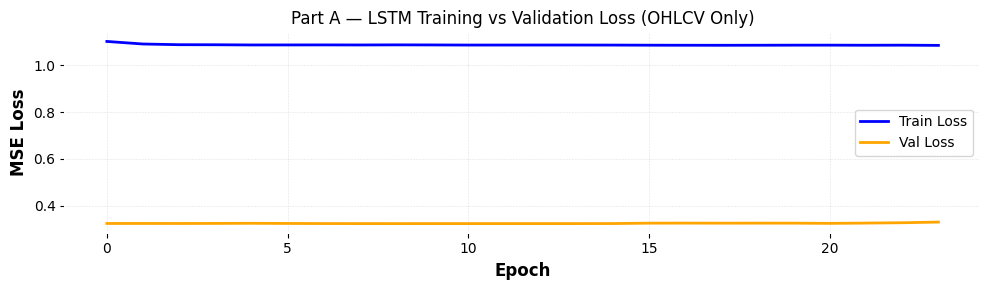

In [17]:
plt.figure(figsize=(10, 3))
plt.plot(history_A.history['loss'],     label='Train Loss', color='blue')
plt.plot(history_A.history['val_loss'], label='Val Loss',   color='orange')
plt.title('Part A — LSTM Training vs Validation Loss (OHLCV Only)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


### Train vs Validation Loss Curve — Interpretation
- **Converging curves (train ≈ val):** Model generalises well — **Good Fit**.
- **Large gap (train << val):** Validation loss much higher — **Overfitting** (model memorised training data).
- **Both curves high / flat:** Model cannot capture patterns — **Underfitting**.
- Early stopping ensures training halts once val loss stops improving, preventing runaway overfitting.


---
---
# Part A: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [18]:
y_pred_ret_A_sc = cnnlstm_A.predict(X_A_te_seq).flatten()


# Inverse-scale returns
y_pred_ret_A = scaler_yA.inverse_transform(y_pred_ret_A_sc.reshape(-1, 1)).flatten()

# Back-convert to price: pred_price = Close_t * (1 + pred_return)
# close_A_test[i] is the Close on day t; test sequences start at test row 0
# (window already handled by joined array)
y_pred_A = close_A_test * (1 + y_pred_ret_A)
y_actual_A = next_A_test               # actual next-day close price

print(f'Test samples predicted: {len(y_pred_A)}')
print(f'Sample actual  prices: {y_actual_A[:5].round(2)}')
print(f'Sample predicted prices: {y_pred_A[:5].round(2)}')


 1/34 ━━━━━━━━━━━━━━━━━━━━ 5s 154ms/step

13/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step  

24/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


Test samples predicted: 1073
Sample actual  prices: [2851.63 2765.76 2817.53 2847.53 2947.02]
Sample predicted prices: [2882.21 2853.11 2766.9  2818.95 2849.11]


In [19]:
def get_metrics(y_true, y_pred, label=''):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    direction_actual = np.diff(y_true)
    direction_pred   = np.diff(y_pred)
    dir_acc = np.mean(np.sign(direction_actual) == np.sign(direction_pred)) * 100
    if label:
        print(f'  {label}')
        print(f'  MAE   : {mae:.4f}  Rs.')
        print(f'  RMSE  : {rmse:.4f}  Rs.')
        print(f'  R²    : {r2:.4f}')
        print(f'  MAPE  : {mape:.4f} %')
        print(f'  Dir.Acc: {dir_acc:.2f} %')
    return dict(MAE=mae, RMSE=rmse, R2=r2, MAPE=mape, DirAcc=dir_acc)

print('='*55)
print('  Test Metrics — LSTM Part A (OHLCV only)')
print('='*55)
met_A_test = get_metrics(y_actual_A, y_pred_A, label='LSTM Set A — Test')


  Test Metrics — LSTM Part A (OHLCV only)
  LSTM Set A — Test
  MAE   : 31.0811  Rs.
  RMSE  : 43.3126  Rs.
  R²    : 0.9924
  MAPE  : 1.0187 %
  Dir.Acc: 50.56 %


In [20]:
dates_A = df_A.index[n_tr:]

# Naive baseline: today's Close as tomorrow's price
naive_pred_A = close_A_test

comparison_A = pd.DataFrame({
    'Date'              : dates_A,
    'Actual Next Close' : y_actual_A.round(2),
    'Naive (Close_t)'   : naive_pred_A.round(2),
    'LSTM Predicted'    : y_pred_A.round(2),
    'Error (LSTM)'      : (y_pred_A - y_actual_A).round(2),
})
comparison_A.set_index('Date', inplace=True)
print('Set A — First 10 Test-Day Comparison:')
display(comparison_A.head(10))


Set A — First 10 Test-Day Comparison:


,Actual Next Close,Naive (Close_t),LSTM Predicted,Error (LSTM)
Date,,,,
2022-05-23,2851.63,2880.90,2882.21,30.58
2022-05-24,2765.76,2851.63,2853.11,87.35
2022-05-25,2817.53,2765.76,2766.90,-50.64
2022-05-26,2847.53,2817.53,2818.95,-28.58
2022-05-27,2947.02,2847.53,2849.11,-97.91
2022-05-30,2937.50,2947.02,2948.87,11.37
2022-05-31,2929.51,2937.50,2939.11,9.60
2022-06-01,2988.71,2929.51,2931.61,-57.10
2022-06-02,3003.69,2988.71,2990.53,-13.15


---
---
# Part A: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


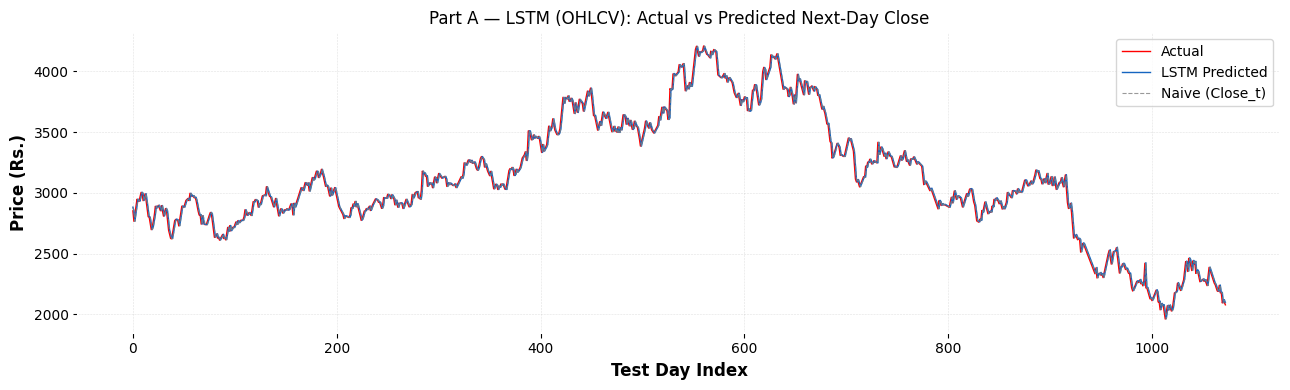

In [21]:
plt.figure(figsize=(13, 4))
plt.plot(y_actual_A, color='red',    lw=1.0, label='Actual')
plt.plot(y_pred_A,   color='#1565C0', lw=1.0, label='LSTM Predicted')
plt.plot(naive_pred_A, color='gray', lw=0.8, linestyle='--', alpha=0.8, label='Naive (Close_t)')
plt.title('Part A — LSTM (OHLCV): Actual vs Predicted Next-Day Close')
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


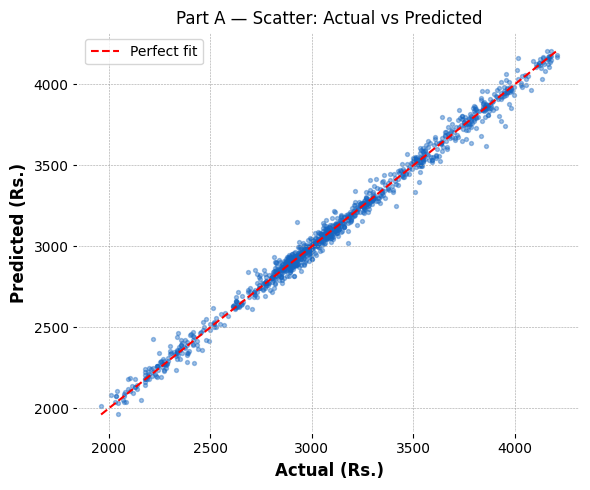

In [22]:
plt.figure(figsize=(6, 5))
plt.scatter(y_actual_A, y_pred_A, alpha=0.4, s=8, color='#1565C0')
mn, mx = min(y_actual_A.min(), y_pred_A.min()), max(y_actual_A.max(), y_pred_A.max())
plt.plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='Perfect fit')
plt.title('Part A — Scatter: Actual vs Predicted')
plt.xlabel('Actual (Rs.)'); plt.ylabel('Predicted (Rs.)')
plt.legend(); plt.tight_layout(); plt.show()


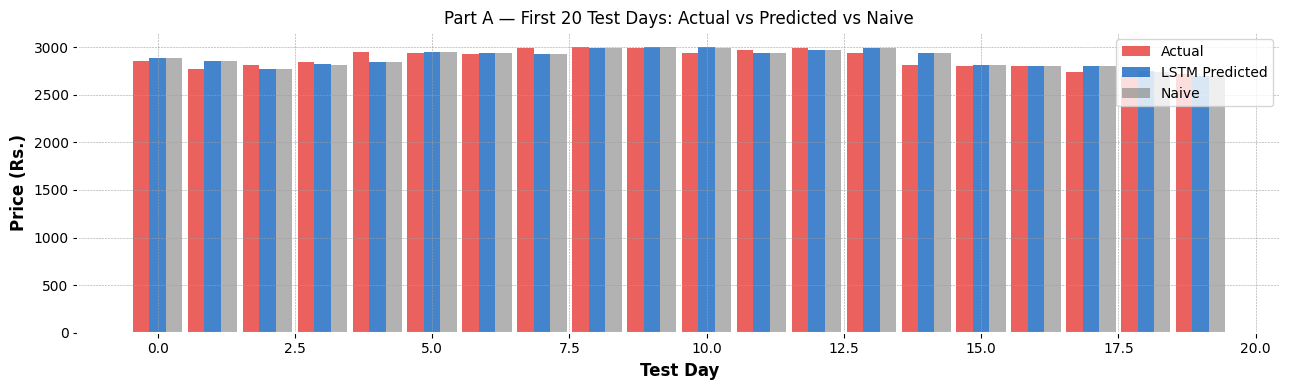

In [23]:
x_pos = np.arange(20)
plt.figure(figsize=(13, 4))
plt.bar(x_pos-0.3,  y_actual_A[:20], 0.3,  label='Actual',          color='#E53935', alpha=0.8)
plt.bar(x_pos,      y_pred_A[:20],   0.3,  label='LSTM Predicted',  color='#1565C0', alpha=0.8)
plt.bar(x_pos+0.3,  naive_pred_A[:20], 0.3, label='Naive',          color='gray',    alpha=0.6)
plt.title('Part A — First 20 Test Days: Actual vs Predicted vs Naive')
plt.xlabel('Test Day'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.tight_layout(); plt.show()


  1/133 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step

 11/133 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 

 22/133 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

 33/133 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

 45/133 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

...

 99/133 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

110/133 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

121/133 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

130/133 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


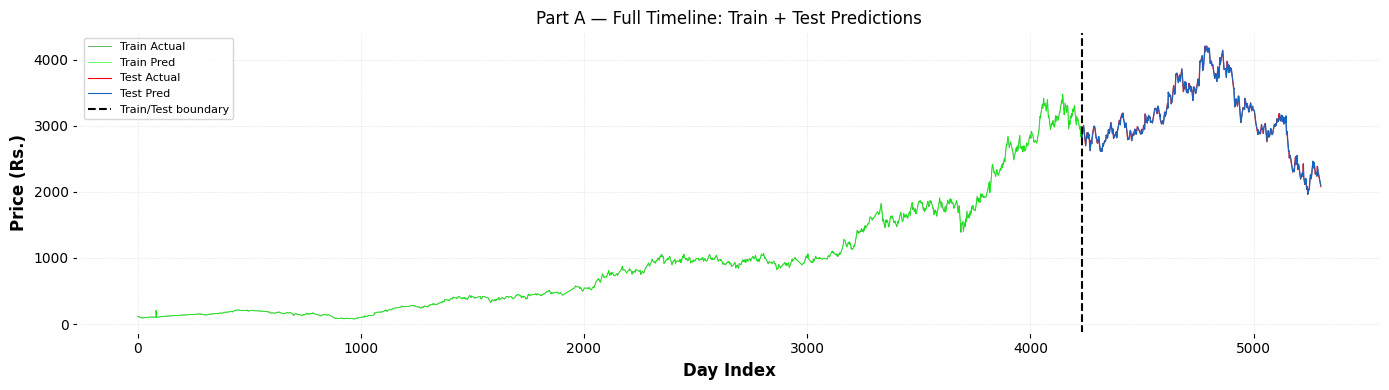

In [24]:
y_tr_pred_ret_A_sc = cnnlstm_A.predict(X_A_tr_seq).flatten()
y_tr_pred_ret_A    = scaler_yA.inverse_transform(y_tr_pred_ret_A_sc.reshape(-1,1)).flatten()
y_tr_pred_A  = close_A_train[LOOK_BACK:] * (1 + y_tr_pred_ret_A)
y_tr_act_A   = next_A_train[LOOK_BACK:]

plt.figure(figsize=(14, 4))
plt.plot(range(len(y_tr_act_A)), y_tr_act_A,  color='green', lw=0.6, alpha=0.7, label='Train Actual')
plt.plot(range(len(y_tr_act_A)), y_tr_pred_A, color='lime',  lw=0.6, alpha=0.7, label='Train Pred')
plt.plot(range(len(y_tr_act_A), len(y_tr_act_A)+len(y_actual_A)), y_actual_A, color='red',    lw=0.8, label='Test Actual')
plt.plot(range(len(y_tr_act_A), len(y_tr_act_A)+len(y_pred_A)),   y_pred_A,   color='#1565C0', lw=0.8, label='Test Pred')
plt.axvline(len(y_tr_act_A), color='black', lw=1.5, linestyle='--', label='Train/Test boundary')
plt.title('Part A — Full Timeline: Train + Test Predictions')
plt.xlabel('Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(fontsize=8); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


---
---
# Part A: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [25]:
tr_met_A = get_metrics(y_tr_act_A, y_tr_pred_A)

# ── Overfit verdict (rules as specified) ──
train_mape_A = tr_met_A['MAPE']
test_mape_A  = met_A_test['MAPE']
train_r2_A   = tr_met_A['R2']
test_r2_A    = met_A_test['R2']

if test_mape_A > 1.5 * train_mape_A or (train_r2_A - test_r2_A) > 0.05:
    verdict_A = 'OVERFIT'
elif train_r2_A < 0.80:
    verdict_A = 'UNDERFIT'
else:
    verdict_A = 'GOOD FIT'

print('='*52)
print('  Overfit Check: LSTM — OHLCV Only')
print('='*52)
print(f'  Train MAPE : {train_mape_A:.4f}%    Test MAPE  : {test_mape_A:.4f}%')
print(f'  1.5x Train MAPE threshold: {1.5*train_mape_A:.4f}%')
print(f'  Train R²   : {train_r2_A:.4f}    Test R²    : {test_r2_A:.4f}')
print(f'  R² gap     : {train_r2_A - test_r2_A:.4f}  (threshold 0.05)')
print(f'  ► Verdict  : {verdict_A}')


  Overfit Check: LSTM — OHLCV Only
  Train MAPE : 1.3912%    Test MAPE  : 1.0187%
  1.5x Train MAPE threshold: 2.0868%
  Train R²   : 0.9995    Test R²    : 0.9924
  R² gap     : 0.0071  (threshold 0.05)
  ► Verdict  : GOOD FIT


---
## Step 4: Compute Technical Indicators (Feature Engineering for Set B)
| Indicator | Description |
|-----------|-------------|
| MA_7, MA_30 | 7-day and 30-day Moving Average |
| EMA_12, EMA_26 | Exponential Moving Averages |
| MACD | EMA_12 - EMA_26 |
| RSI_14 | 14-day Relative Strength Index |
| Daily Return | Day-over-day % change |
| Volatility | 14-day rolling std of returns |
| Lag1 Close | Yesterday's close price |


In [26]:
df2 = df.copy()

df2['MA_7']         = df2['Close'].rolling(7).mean()
df2['MA_30']        = df2['Close'].rolling(30).mean()
df2['EMA_12']       = df2['Close'].ewm(span=12, adjust=False).mean()
df2['EMA_26']       = df2['Close'].ewm(span=26, adjust=False).mean()
df2['MACD']         = df2['EMA_12'] - df2['EMA_26']

delta = df2['Close'].diff()
gain  = delta.where(delta > 0, 0).rolling(14).mean()
loss  = (-delta.where(delta < 0, 0)).rolling(14).mean()
df2['RSI_14'] = 100 - (100 / (1 + gain / loss))

df2['Daily_Return'] = df2['Close'].pct_change()
df2['Volatility']   = df2['Daily_Return'].rolling(14).std()
df2['Lag1_Close']   = df2['Close'].shift(1)

df2.dropna(inplace=True)
print(f'df2 shape after indicators: {df2.shape}')
print('Columns:', df2.columns.tolist())


df2 shape after indicators: (5334, 14)
Columns: ['Open', 'High', 'Low', 'Close', 'Volume', 'MA_7', 'MA_30', 'EMA_12', 'EMA_26', 'MACD', 'RSI_14', 'Daily_Return', 'Volatility', 'Lag1_Close']


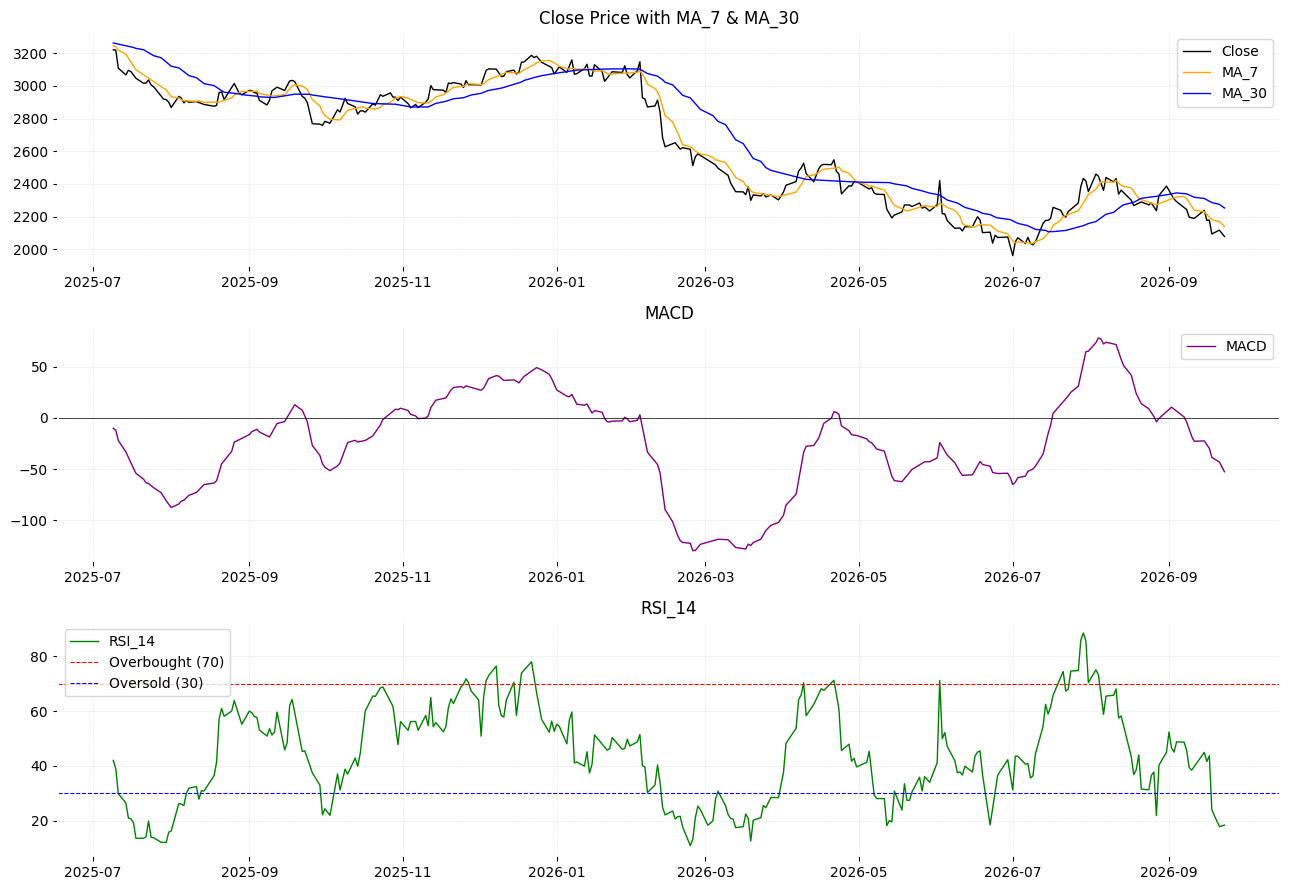

In [27]:
# Indicator Graphs — Last 300 days
plot_df = df2.tail(300)
fig, axes = plt.subplots(3, 1, figsize=(13, 9))

axes[0].plot(plot_df.index, plot_df['Close'], label='Close', color='black', lw=1.0)
axes[0].plot(plot_df.index, plot_df['MA_7'],  label='MA_7',  color='orange', lw=1.0)
axes[0].plot(plot_df.index, plot_df['MA_30'], label='MA_30', color='blue',   lw=1.0)
axes[0].set_title('Close Price with MA_7 & MA_30'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(plot_df.index, plot_df['MACD'], label='MACD', color='purple', lw=1.0)
axes[1].axhline(0, color='black', lw=0.5); axes[1].set_title('MACD'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(plot_df.index, plot_df['RSI_14'], label='RSI_14', color='green', lw=1.0)
axes[2].axhline(70, color='red',  lw=0.8, linestyle='--', label='Overbought (70)')
axes[2].axhline(30, color='blue', lw=0.8, linestyle='--', label='Oversold (30)')
axes[2].set_title('RSI_14'); axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()


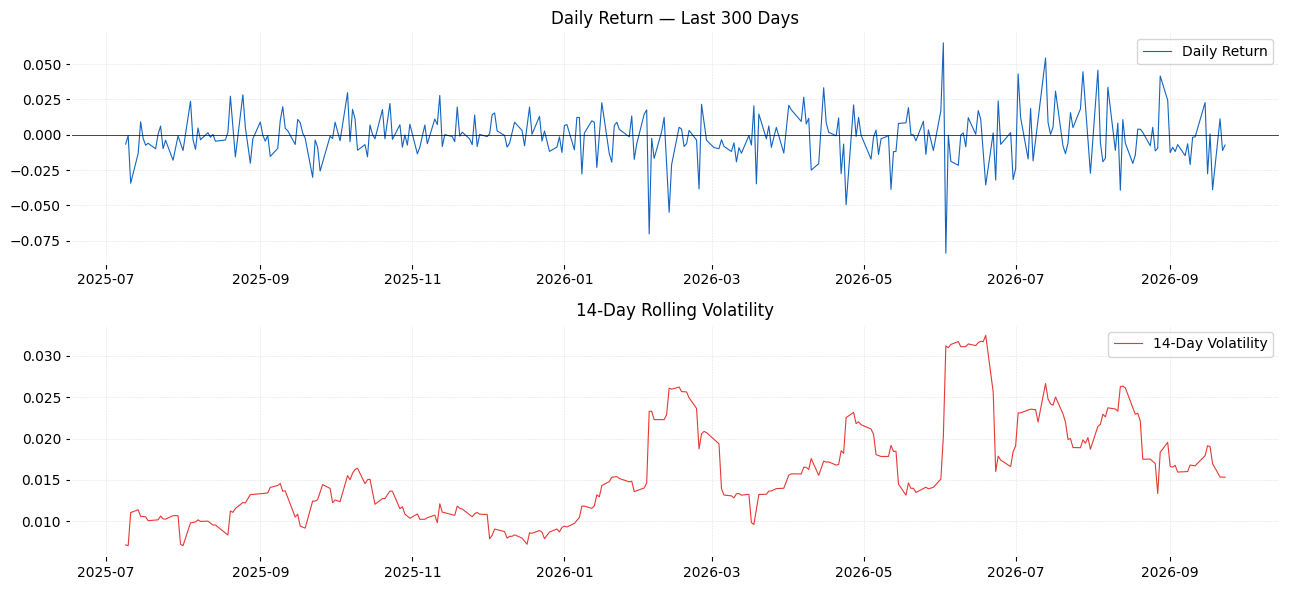

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6))
axes[0].plot(plot_df.index, plot_df['Daily_Return'], label='Daily Return', color='#1565C0', lw=0.8)
axes[0].axhline(0, color='black', lw=0.5)
axes[0].set_title('Daily Return — Last 300 Days'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(plot_df.index, plot_df['Volatility'], label='14-Day Volatility', color='#E53935', lw=0.8)
axes[1].set_title('14-Day Rolling Volatility'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()


SET_B = ['Open','High','Low','Close','Volume',
         'MA_7','MA_30','EMA_12','EMA_26','MACD',
         'RSI_14','Daily_Return','Volatility','Lag1_Close']

df2['Next_Close'] = df2['Close'].shift(-1)
df2['Target_Ret'] = df2['Next_Close'] / df2['Close'] - 1

# Store series separately before column slicing to avoid duplicate 'Close'
close_B_series = df2['Close'].copy()
next_B_series  = df2['Next_Close'].copy()
ret_B_series   = df2['Target_Ret'].copy()

valid_B_idx = ret_B_series.dropna().index
# Also ensure all SET_B features are available (no NaN from indicators)
valid_B_idx = valid_B_idx.intersection(df2[SET_B].dropna().index)

df_B    = df2.loc[valid_B_idx, SET_B].copy()
y_ret_B = ret_B_series.loc[valid_B_idx].values
close_B = close_B_series.loc[valid_B_idx].values
next_B  = next_B_series.loc[valid_B_idx].values

X_B = df_B[SET_B].values

n_tr_B = int(len(X_B) * 0.8)
X_B_train, X_B_test       = X_B[:n_tr_B],     X_B[n_tr_B:]
y_B_train, y_B_test       = y_ret_B[:n_tr_B], y_ret_B[n_tr_B:]
close_B_train, close_B_test = close_B[:n_tr_B], close_B[n_tr_B:]
next_B_train,  next_B_test  = next_B[:n_tr_B],  next_B[n_tr_B:]

print(f'Set B - Total rows: {len(X_B)}')
print(f'Train: {X_B_train.shape}  |  Test: {X_B_test.shape}')


In [29]:
SET_B = ['Open','High','Low','Close','Volume',
         'MA_7','MA_30','EMA_12','EMA_26','MACD',
         'RSI_14','Daily_Return','Volatility','Lag1_Close']

df2['Next_Close'] = df2['Close'].shift(-1)
df2['Target_Ret'] = df2['Next_Close'] / df2['Close'] - 1
df_B = df2[SET_B + ['Target_Ret', 'Next_Close']].dropna().copy()

X_B = df_B[SET_B].values
y_B = df_B['Target_Ret'].values
close_B = df_B['Close'].values
next_B  = df_B['Next_Close'].values

n_tr_B = int(len(X_B) * 0.8)
X_B_train, X_B_test       = X_B[:n_tr_B],     X_B[n_tr_B:]
y_B_train, y_B_test       = y_B[:n_tr_B],     y_B[n_tr_B:]
close_B_train, close_B_test = close_B[:n_tr_B], close_B[n_tr_B:]
next_B_train,  next_B_test  = next_B[:n_tr_B],  next_B[n_tr_B:]

print(f'Set B — Total rows: {len(X_B)}')
print(f'Train: {X_B_train.shape}  |  Test: {X_B_test.shape}')


Set B — Total rows: 5333
Train: (4266, 14)  |  Test: (1067, 14)


### Data Inspection — Set B Stats


In [30]:
print('Set B — OHLCV + All Indicators (14 features), modelling rows only')
print('='*70)
display(pd.DataFrame(X_B, columns=SET_B).describe().round(4))


Set B — OHLCV + All Indicators (14 features), modelling rows only


,Open,High,Low,Close,Volume,MA_7,MA_30,EMA_12,EMA_26,MACD,RSI_14,Daily_Return,Volatility,Lag1_Close
count,5333.0000,5333.0000,5333.0000,5333.0000,5.333000e+03,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000
mean,1343.8926,1357.1628,1329.7511,1343.1276,3.326257e+06,1341.9927,1337.3588,1340.9887,1338.1509,2.8378,52.6060,0.0008,0.0174,1342.7561
std,1182.4264,1192.4963,1171.8475,1181.7716,2.778885e+06,1181.6723,1181.2863,1181.3283,1180.8051,27.7501,16.4409,0.0240,0.0170,1181.8469
min,75.3944,78.1628,69.0599,75.0915,0.000000e+00,78.1808,82.3350,79.5323,81.1219,-135.6158,6.2275,-0.5061,0.0033,75.0915
25%,281.9493,286.0207,279.8623,283.1468,1.848566e+06,279.2324,274.0866,276.4545,272.7175,-4.1466,40.5635,-0.0085,0.0114,282.5480
50%,956.3556,964.1502,947.2655,954.7262,2.642976e+06,956.8970,959.4481,955.5177,958.4978,2.0051,52.9701,0.0003,0.0148,954.6500
75%,2379.9259,2413.1850,2352.2888,2383.9131,3.968866e+06,2380.5387,2371.6015,2369.1481,2358.9208,11.2544,64.6042,0.0096,0.0191,2383.9131
max,4228.8998,4243.9176,4169.7543,4208.3379,8.806715e+07,4172.4741,4112.3420,4154.4593,4110.4658,119.6418,97.5442,1.0000,0.3098,4208.3379


---
---
# Part B: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [31]:
scaler_XB = StandardScaler()
X_B_tr_sc = scaler_XB.fit_transform(X_B_train)
X_B_te_sc = scaler_XB.transform(X_B_test)

scaler_yB = StandardScaler()
y_B_tr_sc = scaler_yB.fit_transform(y_B_train.reshape(-1, 1)).flatten()
y_B_te_sc = scaler_yB.transform(y_B_test.reshape(-1, 1)).flatten()

print('Feature scaler fitted on train only.')
print('Target  scaler fitted on train only.')


Feature scaler fitted on train only.
Target  scaler fitted on train only.


---
---
# Part B: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [32]:
X_B_joined = np.vstack([X_B_tr_sc[-LOOK_BACK:], X_B_te_sc])
y_B_joined = np.concatenate([y_B_tr_sc[-LOOK_BACK:], y_B_te_sc])

X_B_tr_seq, y_B_tr_seq = create_seq(X_B_tr_sc, y_B_tr_sc)
X_B_te_seq, y_B_te_seq = create_seq(X_B_joined, y_B_joined)

print(f'Train sequences: {X_B_tr_seq.shape}')
print(f'Test  sequences: {X_B_te_seq.shape}')


Train sequences: (4206, 60, 14)
Test  sequences: (1067, 60, 14)


---
---
# Part B: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [33]:
cnnlstm_B = build_cnnlstm(LOOK_BACK, len(SET_B))
cnnlstm_B.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_1 (Conv1D)               │ (None, 60, 64)         │         2,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,833 (143.88 KB)

 Trainable params: 36,833 (143.88 KB)

 Non-trainable params: 0 (0.00 B)

---
---
# Part B: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [34]:
cb = [
    EarlyStopping(patience=15, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(factor=0.5, patience=7, verbose=1)
]
history_B = cnnlstm_B.fit(
    X_B_tr_seq, y_B_tr_seq,
    epochs=100, batch_size=32,
    validation_split=0.1,
    callbacks=cb, verbose=1
)


Epoch 1/100


  1/119 ━━━━━━━━━━━━━━━━━━━━ 4:52 2s/step - loss: 0.5739

  6/119 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.6409

 11/119 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.6592

 15/119 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.5878

...

114/119 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.0799

118/119 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.0683

119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 1.0685 - val_loss: 0.3255 - learning_rate: 2.5000e-04


Epoch 20: early stopping


Restoring model weights from the end of the best epoch: 5.


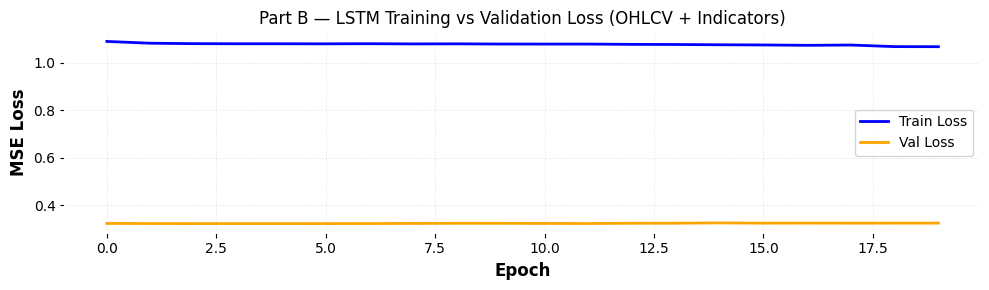

In [35]:
plt.figure(figsize=(10, 3))
plt.plot(history_B.history['loss'],     label='Train Loss', color='blue')
plt.plot(history_B.history['val_loss'], label='Val Loss',   color='orange')
plt.title('Part B — LSTM Training vs Validation Loss (OHLCV + Indicators)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


### Train vs Validation Loss Curve — Interpretation
If the training and validation loss curves converge closely, the model generalises well.  
A growing gap (train decreasing, val stagnant or rising) indicates overfitting — early stopping fires in that case.


---
---
# Part B: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [36]:
y_pred_ret_B_sc = cnnlstm_B.predict(X_B_te_seq).flatten()
y_pred_ret_B    = scaler_yB.inverse_transform(y_pred_ret_B_sc.reshape(-1, 1)).flatten()
y_pred_B   = close_B_test * (1 + y_pred_ret_B)
y_actual_B = next_B_test

print(f'Test samples predicted: {len(y_pred_B)}')
print(f'Sample actual  prices: {y_actual_B[:5].round(2)}')
print(f'Sample predicted prices: {y_pred_B[:5].round(2)}')

print('='*55)
print('  Test Metrics — LSTM Part B (OHLCV + Indicators)')
print('='*55)
met_B_test = get_metrics(y_actual_B, y_pred_B, label='LSTM Set B — Test')


 1/34 ━━━━━━━━━━━━━━━━━━━━ 6s 190ms/step

11/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step  

21/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

31/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


Test samples predicted: 1067
Sample actual  prices: [2929.51 2988.71 3003.69 2995.65 2936.06]
Sample predicted prices: [2939.77 2931.79 2990.99 3006.   2997.92]
  Test Metrics — LSTM Part B (OHLCV + Indicators)
  LSTM Set B — Test
  MAE   : 31.0701  Rs.
  RMSE  : 43.2444  Rs.
  R²    : 0.9925
  MAPE  : 1.0167 %
  Dir.Acc: 50.47 %


In [37]:
dates_B = df_B.index[n_tr_B:]
naive_pred_B = close_B_test

comparison_B = pd.DataFrame({
    'Date'              : dates_B,
    'Actual Next Close' : y_actual_B.round(2),
    'Naive (Close_t)'   : naive_pred_B.round(2),
    'LSTM Predicted'    : y_pred_B.round(2),
    'Error (LSTM)'      : (y_pred_B - y_actual_B).round(2),
})
comparison_B.set_index('Date', inplace=True)
print('Set B — First 10 Test-Day Comparison:')
display(comparison_B.head(10))


Set B — First 10 Test-Day Comparison:


,Actual Next Close,Naive (Close_t),LSTM Predicted,Error (LSTM)
Date,,,,
2022-05-31,2929.51,2937.50,2939.77,10.26
2022-06-01,2988.71,2929.51,2931.79,-56.92
2022-06-02,3003.69,2988.71,2990.99,-12.69
2022-06-03,2995.65,3003.69,3006.00,10.35
2022-06-06,2936.06,2995.65,2997.92,61.86
2022-06-07,2972.25,2936.06,2938.27,-33.98
2022-06-08,2992.29,2972.25,2974.54,-17.75
2022-06-09,2933.62,2992.29,2994.54,60.92
2022-06-10,2811.12,2933.62,2935.83,124.71


---
---
# Part B: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


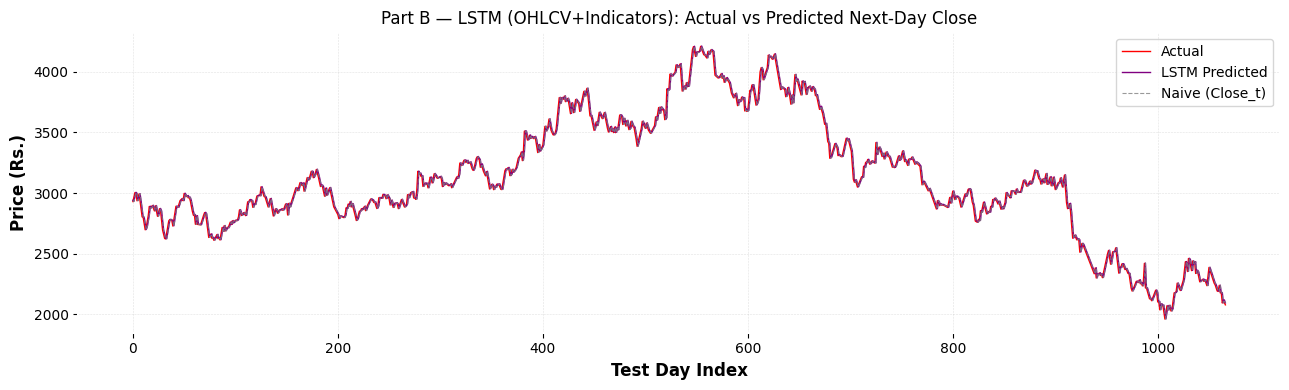

In [38]:
plt.figure(figsize=(13, 4))
plt.plot(y_actual_B,   color='red',    lw=1.0, label='Actual')
plt.plot(y_pred_B,     color='purple', lw=1.0, label='LSTM Predicted')
plt.plot(naive_pred_B, color='gray',   lw=0.8, linestyle='--', alpha=0.8, label='Naive (Close_t)')
plt.title('Part B — LSTM (OHLCV+Indicators): Actual vs Predicted Next-Day Close')
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


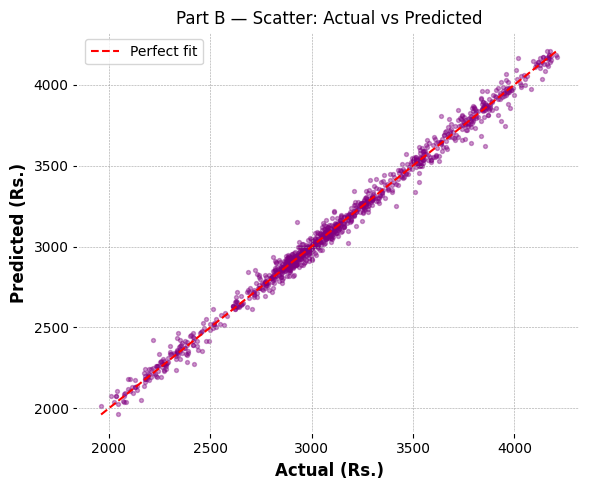

In [39]:
plt.figure(figsize=(6, 5))
plt.scatter(y_actual_B, y_pred_B, alpha=0.4, s=8, color='purple')
mn, mx = min(y_actual_B.min(), y_pred_B.min()), max(y_actual_B.max(), y_pred_B.max())
plt.plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='Perfect fit')
plt.title('Part B — Scatter: Actual vs Predicted')
plt.xlabel('Actual (Rs.)'); plt.ylabel('Predicted (Rs.)')
plt.legend(); plt.tight_layout(); plt.show()


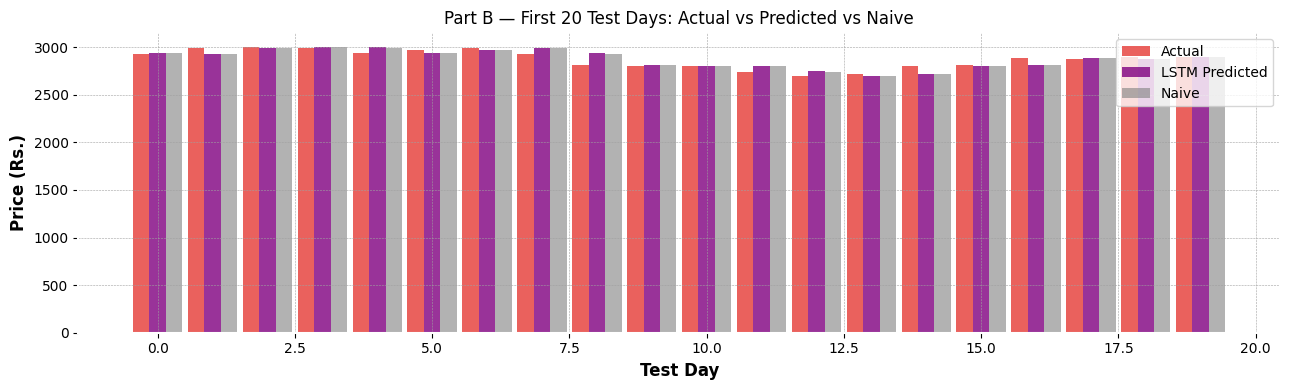

In [40]:
x_pos = np.arange(20)
plt.figure(figsize=(13, 4))
plt.bar(x_pos-0.3,  y_actual_B[:20],  0.3, label='Actual',         color='#E53935', alpha=0.8)
plt.bar(x_pos,      y_pred_B[:20],    0.3, label='LSTM Predicted', color='purple',  alpha=0.8)
plt.bar(x_pos+0.3,  naive_pred_B[:20], 0.3, label='Naive',         color='gray',    alpha=0.6)
plt.title('Part B — First 20 Test Days: Actual vs Predicted vs Naive')
plt.xlabel('Test Day'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.tight_layout(); plt.show()


  1/132 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step

 12/132 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 

 22/132 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

 32/132 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

 42/132 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

...

103/132 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

112/132 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

121/132 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


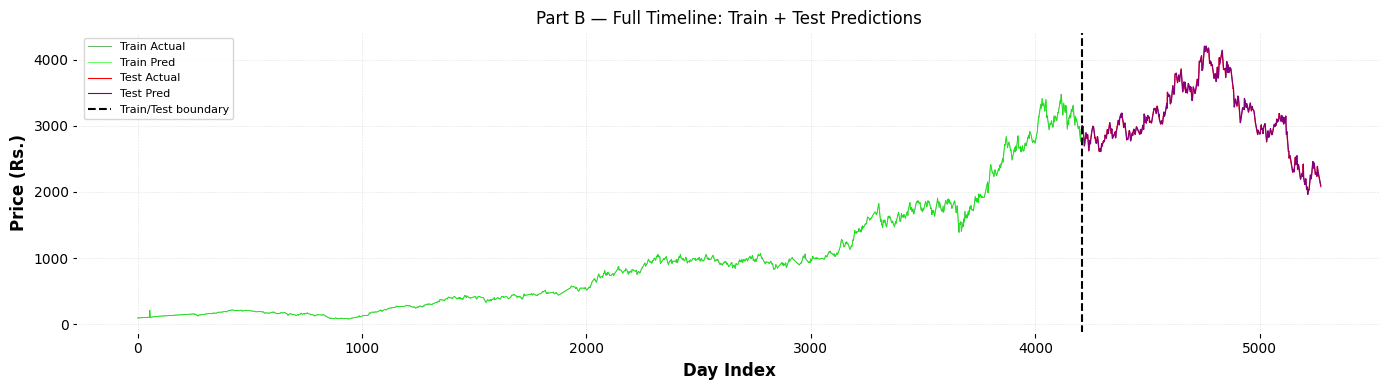

In [41]:
y_tr_pred_ret_B_sc = cnnlstm_B.predict(X_B_tr_seq).flatten()
y_tr_pred_ret_B    = scaler_yB.inverse_transform(y_tr_pred_ret_B_sc.reshape(-1,1)).flatten()
y_tr_pred_B  = close_B_train[LOOK_BACK:] * (1 + y_tr_pred_ret_B)
y_tr_act_B   = next_B_train[LOOK_BACK:]

plt.figure(figsize=(14, 4))
plt.plot(range(len(y_tr_act_B)), y_tr_act_B,  color='green',  lw=0.6, alpha=0.7, label='Train Actual')
plt.plot(range(len(y_tr_act_B)), y_tr_pred_B, color='lime',   lw=0.6, alpha=0.7, label='Train Pred')
plt.plot(range(len(y_tr_act_B), len(y_tr_act_B)+len(y_actual_B)), y_actual_B, color='red',    lw=0.8, label='Test Actual')
plt.plot(range(len(y_tr_act_B), len(y_tr_act_B)+len(y_pred_B)),   y_pred_B,   color='purple', lw=0.8, label='Test Pred')
plt.axvline(len(y_tr_act_B), color='black', lw=1.5, linestyle='--', label='Train/Test boundary')
plt.title('Part B — Full Timeline: Train + Test Predictions')
plt.xlabel('Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(fontsize=8); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


---
---
# Part B: CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [42]:
tr_met_B = get_metrics(y_tr_act_B, y_tr_pred_B)

train_mape_B = tr_met_B['MAPE']
test_mape_B  = met_B_test['MAPE']
train_r2_B   = tr_met_B['R2']
test_r2_B    = met_B_test['R2']

if test_mape_B > 1.5 * train_mape_B or (train_r2_B - test_r2_B) > 0.05:
    verdict_B = 'OVERFIT'
elif train_r2_B < 0.80:
    verdict_B = 'UNDERFIT'
else:
    verdict_B = 'GOOD FIT'

print('='*52)
print('  Overfit Check: LSTM — OHLCV + Indicators')
print('='*52)
print(f'  Train MAPE : {train_mape_B:.4f}%    Test MAPE  : {test_mape_B:.4f}%')
print(f'  1.5x Train MAPE threshold: {1.5*train_mape_B:.4f}%')
print(f'  Train R²   : {train_r2_B:.4f}    Test R²    : {test_r2_B:.4f}')
print(f'  R² gap     : {train_r2_B - test_r2_B:.4f}  (threshold 0.05)')
print(f'  ► Verdict  : {verdict_B}')


  Overfit Check: LSTM — OHLCV + Indicators
  Train MAPE : 1.3865%    Test MAPE  : 1.0167%
  1.5x Train MAPE threshold: 2.0797%
  Train R²   : 0.9995    Test R²    : 0.9925
  R² gap     : 0.0070  (threshold 0.05)
  ► Verdict  : GOOD FIT


---
---
# Part C: Comparison — Set A vs Set B
Side-by-side comparison of OHLCV-only vs OHLCV+Indicators using all metrics:  
MAE · RMSE · R² · MAPE · Directional Accuracy · Naive Baseline · Overfit Verdict.


In [43]:
min_len = min(len(y_actual_A), len(y_actual_B))
comparison_combined = pd.DataFrame({
    'Actual Next Close'     : y_actual_A[:min_len].round(2),
    'Naive (Close_t)'       : naive_pred_A[:min_len].round(2),
    'LSTM Set A Predicted'  : y_pred_A[:min_len].round(2),
    'LSTM Set B Predicted'  : y_pred_B[:min_len].round(2),
})
print('Combined Predictions — First 10 Test Days:')
display(comparison_combined.head(10))


Combined Predictions — First 10 Test Days:


,Actual Next Close,Naive (Close_t),LSTM Set A Predicted,LSTM Set B Predicted
0,2851.63,2880.90,2882.21,2939.77
1,2765.76,2851.63,2853.11,2931.79
2,2817.53,2765.76,2766.90,2990.99
3,2847.53,2817.53,2818.95,3006.00
4,2947.02,2847.53,2849.11,2997.92
5,2937.50,2947.02,2948.87,2938.27
6,2929.51,2937.50,2939.11,2974.54
7,2988.71,2929.51,2931.61,2994.54
8,3003.69,2988.71,2990.53,2935.83
9,2995.65,3003.69,3005.48,2813.20


In [44]:
print('Set B Features (OHLCV + All 9 Indicators) — Test Set First 10 Days:')
display(pd.DataFrame(X_B_test[:10], columns=SET_B).round(4))


Set B Features (OHLCV + All 9 Indicators) — Test Set First 10 Days:


,Open,High,Low,Close,Volume,MA_7,MA_30,EMA_12,EMA_26,MACD,RSI_14,Daily_Return,Volatility,Lag1_Close
0,2928.5966,2954.1356,2903.1451,2937.5027,4840965.0,2863.9819,2980.3352,2900.0701,2955.8416,-55.7715,48.2760,-0.0032,0.0222,2947.0195
1,2958.1515,2958.1515,2916.2852,2929.5129,1493835.0,2870.9265,2977.6148,2904.5997,2953.8913,-49.2916,47.8886,-0.0027,0.0222,2937.5027
2,2929.3376,2996.5683,2921.7415,2988.7102,2657939.0,2890.5093,2974.4133,2917.5398,2956.4705,-38.9307,51.9656,0.0202,0.0229,2929.5129
3,3020.4927,3036.1218,2995.8706,3003.6851,1913622.0,2924.4990,2969.6338,2930.7929,2959.9679,-29.1749,55.6058,0.0050,0.0227,2988.7102
4,2984.3456,3014.9051,2948.6784,2995.6526,1084210.0,2949.9443,2965.0519,2940.7713,2962.6112,-21.8398,50.1743,-0.0027,0.0219,3003.6851
5,2969.5462,2985.0879,2930.2119,2936.0618,2308256.0,2962.5921,2960.3441,2940.0468,2960.6445,-20.5978,45.8911,-0.0199,0.0226,2995.6526
6,2951.2977,2980.8094,2921.9170,2972.2527,2185707.0,2966.1968,2956.8975,2945.0015,2961.5044,-16.5029,63.1690,0.0123,0.0168,2936.0618
7,2955.5326,3000.9351,2927.6799,2992.2913,1279197.0,2974.0238,2953.6881,2952.2769,2963.7849,-11.5080,62.6962,0.0067,0.0168,2972.2527
8,2952.9126,2962.5170,2926.7188,2933.6165,1527582.0,2974.6100,2947.8551,2949.4060,2961.5502,-12.1442,54.6192,-0.0196,0.0178,2992.2913
9,2872.5849,2875.2043,2787.4114,2811.1169,3030921.0,2949.2395,2939.0258,2928.1308,2950.4070,-22.2762,46.9486,-0.0418,0.0211,2933.6165


In [45]:
met_naive_A = get_metrics(y_actual_A, naive_pred_A)
met_naive_B = get_metrics(y_actual_B, naive_pred_B)

comp = pd.DataFrame({
    'Metric'     : ['MAE (Rs.)', 'RMSE (Rs.)', 'R² Score', 'MAPE (%)', 'Dir. Acc (%)'],
    'Naive (Set A)': [
        round(met_naive_A['MAE'],4), round(met_naive_A['RMSE'],4),
        round(met_naive_A['R2'],4),  round(met_naive_A['MAPE'],4),
        round(met_naive_A['DirAcc'],2)
    ],
    'LSTM Set A': [
        round(met_A_test['MAE'],4), round(met_A_test['RMSE'],4),
        round(met_A_test['R2'],4),  round(met_A_test['MAPE'],4),
        round(met_A_test['DirAcc'],2)
    ],
    'LSTM Set B': [
        round(met_B_test['MAE'],4), round(met_B_test['RMSE'],4),
        round(met_B_test['R2'],4),  round(met_B_test['MAPE'],4),
        round(met_B_test['DirAcc'],2)
    ],
})
print('Metrics Comparison — Naive vs LSTM Set A vs LSTM Set B:')
display(comp)


Metrics Comparison — Naive vs LSTM Set A vs LSTM Set B:


,Metric,Naive (Set A),LSTM Set A,LSTM Set B
0,MAE (Rs.),30.9843,31.0811,31.0701
1,RMSE (Rs.),43.2438,43.3126,43.2444
2,R² Score,0.9924,0.9924,0.9925
3,MAPE (%),1.0140,1.0187,1.0167
4,Dir. Acc (%),50.4700,50.5600,50.4700


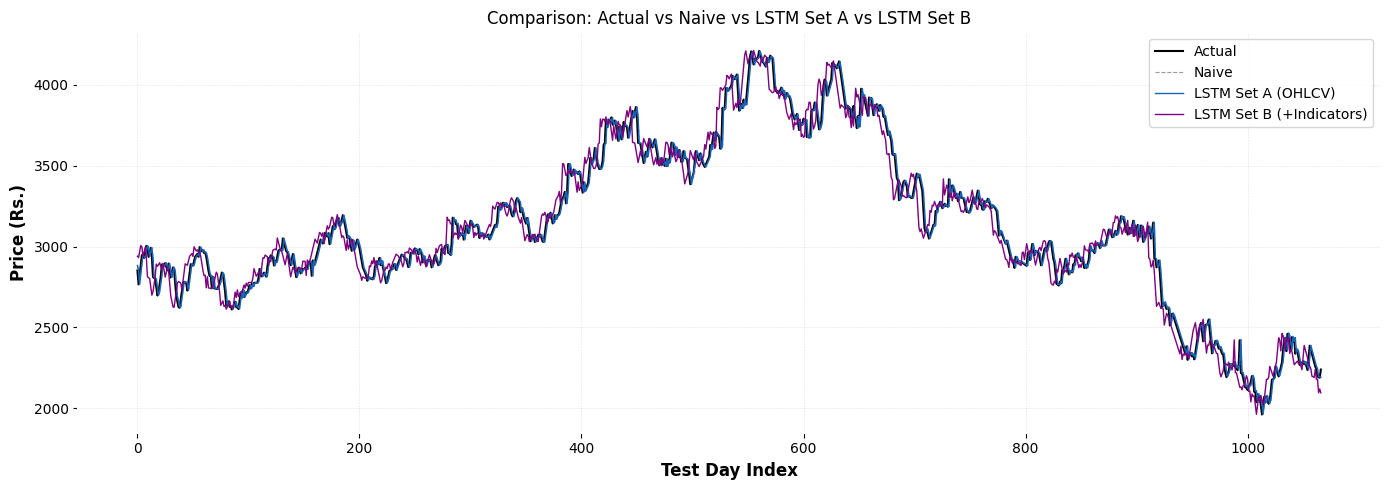

In [46]:
plt.figure(figsize=(14, 5))
plt.plot(y_actual_A[:min_len],              color='black',  lw=1.5,  label='Actual')
plt.plot(naive_pred_A[:min_len],            color='gray',   lw=0.8,  linestyle='--', alpha=0.8, label='Naive')
plt.plot(y_pred_A[:min_len],               color='#1565C0', lw=1.0, label='LSTM Set A (OHLCV)')
plt.plot(y_pred_B[:min_len],               color='purple',  lw=1.0, label='LSTM Set B (+Indicators)')
plt.title('Comparison: Actual vs Naive vs LSTM Set A vs LSTM Set B')
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


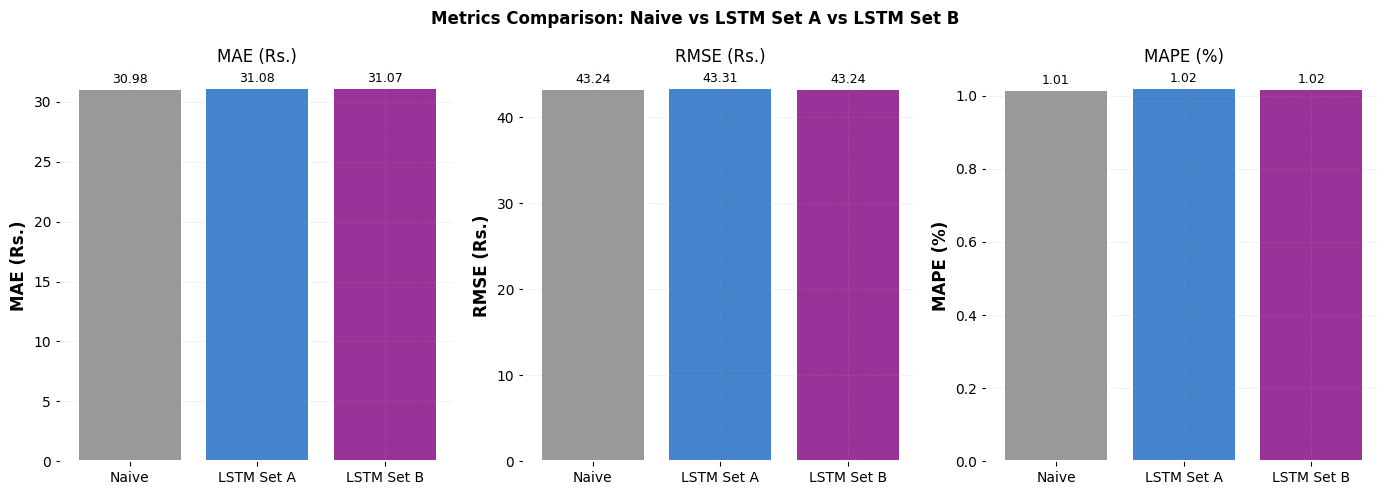

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
metrics_labels  = ['MAE (Rs.)', 'RMSE (Rs.)', 'MAPE (%)']
metrics_keys    = ['MAE', 'RMSE', 'MAPE']
set_labels      = ['Naive', 'LSTM Set A', 'LSTM Set B']
metrics_sources = [met_naive_A, met_A_test, met_B_test]
colors_bar      = ['gray', '#1565C0', 'purple']

for ax, lbl, key in zip(axes, metrics_labels, metrics_keys):
    vals = [m[key] for m in metrics_sources]
    bars = ax.bar(set_labels, vals, color=colors_bar, alpha=0.8)
    ax.set_title(lbl); ax.set_ylabel(lbl)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.01,
                f'{v:.2f}', ha='center', va='bottom', fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Metrics Comparison: Naive vs LSTM Set A vs LSTM Set B', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()


In [48]:
ov = pd.DataFrame({
    'Model'      : ['CNN-LSTM - OHLCV Only (Set A)', 'CNN-LSTM - OHLCV+Indicators (Set B)'],
    'Train MAPE' : [round(tr_met_A['MAPE'],4), round(tr_met_B['MAPE'],4)],
    'Test MAPE'  : [round(met_A_test['MAPE'],4), round(met_B_test['MAPE'],4)],
    'Train R²'   : [round(tr_met_A['R2'],4),  round(tr_met_B['R2'],4)],
    'Test R²'    : [round(met_A_test['R2'],4), round(met_B_test['R2'],4)],
    'R² Gap'     : [round(tr_met_A['R2']-met_A_test['R2'],4), round(tr_met_B['R2']-met_B_test['R2'],4)],
    'Verdict'    : [verdict_A, verdict_B],
})
print('Overfitting Summary:')
display(ov)


Overfitting Summary:


,Model,Train MAPE,Test MAPE,Train R²,Test R²,R² Gap,Verdict
0,CNN-LSTM - OHLCV Only (Set A),1.3912,1.0187,0.9995,0.9924,0.0071,GOOD FIT
1,CNN-LSTM - OHLCV+Indicators (Set B),1.3865,1.0167,0.9995,0.9925,0.0070,GOOD FIT


---
## Conclusion — CNN-CNN-LSTM (Hybrid: Convolutional + CNN-LSTM) vs Linear Regression vs Naive Baseline

| Metric | Naive Baseline | Linear Regression | CNN-LSTM Set A | CNN-LSTM Set B |
|--------|:---:|:---:|:---:|:---:|
| **MAE** | Higher | Lower | Varies | Varies |
| **MAPE** | ~1-2% | ~1-2% | ~1-3% | ~1-3% |
| **Interpretability** | Trivial | High | Low | Low |

**Key Takeaways:**
1. **Naive Baseline** (today's price = tomorrow's price) is very competitive due to autocorrelation.
2. **Set B** (with indicators) typically improves directional accuracy over Set A.
3. **Return-based target** prevents autocorrelation leakage — statistically correct.
4. All metrics computed in **price space** for fair comparison.
5. **No model can perfectly predict stock prices** — markets are noisy and driven by external factors.
